<a href="https://colab.research.google.com/github/hacaizacr/sp500_trend_classifier/blob/main/Grupo2_FinancialModel_v2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Grupo 2 - Proyecto Integrador: ¿qué acciones del S&P 500 superan al mercado?

**Parte Big Data.** Este notebook construye un dataset **limpio y en formato panel (Ticker × Año)** para que el compañero de Machine Learning entrene 3 modelos.

## Decisiones de diseño (y por qué)

| Decisión | Qué hacemos | Por qué |
|---|---|---|
| **Panel Ticker × Año** | Una fila por empresa y por año (no una sola fila con 5 años) | El modelo ve cómo cambian los fundamentales con el tiempo y aprende patrones de cada año |
| **Membresía real del índice** | En cada año solo entran empresas que **estaban en el S&P 500 en esa fecha** (se reconstruye con la tabla de cambios de Wikipedia) | Así el conjunto de empresas cambia año a año, reflejando entradas y salidas |
| **Fundamentales de SEC EDGAR** | Ingresos, utilidad, EPS, deuda y patrimonio de los reportes oficiales 10-K | Permite 10+ años (Yahoo solo da ~4) y trae la **fecha exacta de publicación** de cada reporte |
| **Datos "point-in-time"** | Cada cifra es la que se publicó **por primera vez**, y se observa el día después de su publicación | Evita *data leakage*: el modelo nunca ve información que el mercado aún no conocía |
| **Target relativo** | Target = 1 si la acción rindió **más que el S&P 500 equiponderado (RSP)** en los 12 meses siguientes | Quita el efecto de "año bueno / año malo" y responde la pregunta real de un inversionista: ¿vale la pena elegir esta acción en vez de comprar el índice? |

## Pasos del notebook
| Paso | Qué hace |
|---|---|
| 0 | Configuración y parámetros |
| 1 | Tabla 1 – Wikipedia: sectores + historial de entradas/salidas del índice |
| 2 | Universo de empresas y su código oficial de la SEC (CIK) |
| 3 | Tabla 2 – Yahoo Finance: precios, splits y benchmarks (RSP y SPY) |
| 4 | Tabla 3 – SEC EDGAR: fundamentales anuales |
| 5 | Construcción del panel (features + Target) |
| 6 | Filtro por membresía real del S&P 500 |
| 7 | Limpieza (infinitos, outliers, nulos) |
| 8 | Análisis exploratorio |
| 9 | Exportación y notas para el compañero de ML |

## Paso 0 – Configuración

Todos los parámetros ajustables están aquí. Si hay que cambiar algo (horizonte, benchmark, tamaño de muestra), solo se edita esta celda.

- **`USER_AGENT_SEC`**: la SEC **exige** identificarte en cada petición (nombre y correo). Sin esto bloquea la descarga. **Edítalo antes de ejecutar.**
- **`BENCHMARK = "RSP"`**: ETF del S&P 500 *equiponderado* (cada empresa pesa igual, igual que en nuestro dataset). Es la vara contra la que se mide cada acción.
- **`BENCHMARK_2 = "SPY"`**: ETF del S&P 500 normal (ponderado por tamaño). No define el Target principal; se guarda como columna extra para comparar en el informe.
- **`N_TICKERS = None`**: usa todas las empresas disponibles (~500+). Pon un número (por ejemplo 100) para hacer pruebas rápidas.
- **`HORIZONTE_DIAS = 365`**: horizonte de predicción (12 meses).
- **`LAG_PUBLICACION_DIAS = 1`**: se observa un día *después* de que la empresa publicó el reporte, por si salió tras el cierre del mercado.

In [4]:
import os, io, time, json, warnings
import numpy as np
import pandas as pd
import requests
import yfinance as yf
import matplotlib.pyplot as plt
import seaborn as sns
warnings.filterwarnings("ignore")

# ---------------- PARÁMETROS ----------------
USER_AGENT_SEC       = "Harold Caiza haroldstevenxs@gmail.com"   # nombre + correo (lo exige la SEC)  # <-- OBLIGATORIO: edítalo con tu nombre y correo
FECHA_INICIO_PRECIOS = "2014-01-01"
ANIO_OBS_MIN         = 2015      # primer año de observación del panel
HORIZONTE_DIAS       = 365       # horizonte de predicción (12 meses)
LAG_PUBLICACION_DIAS = 1         # se observa 1 día después de la publicación del reporte
BENCHMARK            = "RSP"     # S&P 500 equiponderado (define el Target)
BENCHMARK_2          = "SPY"     # S&P 500 normal (solo para comparar)
N_TICKERS            = None      # None = todas; o un número para pruebas
SEED                 = 42

HEADERS_SEC = {"User-Agent": USER_AGENT_SEC, "Accept-Encoding": "gzip, deflate"}
FEATURES = ['Revenue_Growth', 'Net_Income', 'Profit_Margin', 'Debt_to_Equity', 'PE_Ratio']
print("Parámetros cargados.")

Parámetros cargados.


## Paso 1 – Tabla 1: Wikipedia (sectores + historial de cambios del índice)

La página de Wikipedia tiene **dos tablas** que usamos:
- **Tabla 0:** las ~503 empresas *actuales* del S&P 500 con su sector GICS.
- **Tabla 1:** los *cambios históricos*: qué ticker entró, cuál salió y en qué fecha.

Los tickers se estandarizan (`BRK.B` → `BRK-B`) porque Yahoo y la SEC usan guion.

> ⚠️ Wikipedia solo da el sector de las empresas **actuales**. Las que ya salieron del índice no traen sector aquí; se recupera después desde Yahoo Finance (Paso 7).

In [6]:
url_wiki = "https://en.wikipedia.org/wiki/List_of_S%26P_500_companies"
url_hist = "https://en.wikipedia.org/wiki/Historical_components_of_the_S%26P_500"
headers = {"User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/120.0.0.0 Safari/537.36"}

def _leer_tablas(url):
    resp = requests.get(url, headers=headers, timeout=30)
    resp.raise_for_status()
    return pd.read_html(io.StringIO(resp.text))

def _aplanar(cols):
    return ["_".join(dict.fromkeys(str(x) for x in c)) if isinstance(c, tuple) else str(c) for c in cols]

# --- Tabla 0: composición actual + sector ---
tablas_wiki = _leer_tablas(url_wiki)
df_wiki = tablas_wiki[0][['Symbol', 'Security', 'GICS Sector']].copy()
df_wiki['Ticker'] = df_wiki['Symbol'].str.replace('.', '-', regex=False).str.strip()
df_wiki = df_wiki.drop(columns=['Symbol'])
print(f"✓ Composición actual: {len(df_wiki)} empresas")

# --- Historial de cambios: se busca en AMBAS páginas cualquier tabla con columnas Added y Removed ---
def _extraer_cambios(t):
    t = t.copy()
    t.columns = _aplanar(t.columns)
    if not (any('Added' in c for c in t.columns) and any('Removed' in c for c in t.columns)):
        return None
    def col(palabra):
        cand = [c for c in t.columns if palabra in c]
        mejores = [c for c in cand if 'Ticker' in c or 'Symbol' in c]
        return (mejores or cand)[0]
    c_fecha = next((c for c in t.columns if 'Effective' in c or 'Date' in c), t.columns[0])
    out = pd.DataFrame({
        'Fecha':   pd.to_datetime(t[c_fecha], errors='coerce'),
        'Added':   t[col('Added')].astype(str).str.replace('.', '-', regex=False).str.strip(),
        'Removed': t[col('Removed')].astype(str).str.replace('.', '-', regex=False).str.strip(),
    })
    return out.dropna(subset=['Fecha'])

partes = []
for url in [url_wiki, url_hist]:
    try:
        tablas = tablas_wiki if url == url_wiki else _leer_tablas(url)
    except Exception as e:
        print(f"  ⚠ No se pudo leer {url.split('/')[-1]}: {e}")
        continue
    encontrados = [x for x in (_extraer_cambios(t) for t in tablas) if x is not None and len(x)]
    print(f"  {url.split('/')[-1]}: {len(tablas)} tablas, {len(encontrados)} con historial de cambios")
    partes += encontrados
    if partes:
        break

if partes:
    df_cambios = (pd.concat(partes, ignore_index=True)
                    .replace({'nan': np.nan, '': np.nan})
                    .drop_duplicates()
                    .reset_index(drop=True))
    print(f"✓ Cambios históricos: {len(df_cambios)} (desde {df_cambios['Fecha'].min().date()})")
else:
    df_cambios = pd.DataFrame({'Fecha': pd.to_datetime([]), 'Added': [], 'Removed': []})
    print("⚠ ADVERTENCIA: no se encontró el historial de cambios del índice.")
    print("  El notebook continuará usando SOLO la lista actual del S&P 500 (sin entradas/salidas).")
    print("  Esto aumenta el sesgo de supervivencia y debe mencionarse en el informe.")

✓ Composición actual: 503 empresas
  List_of_S%26P_500_companies: 2 tablas, 0 con historial de cambios
  Historical_components_of_the_S%26P_500: 2 tablas, 1 con historial de cambios
✓ Cambios históricos: 414 (desde 1976-07-01)


### Reconstrucción de la membresía en cualquier fecha

Partimos de la lista **actual** y "deshacemos" los cambios hacia atrás: si un ticker fue **agregado** después de la fecha, se quita; si fue **removido** después de la fecha, se vuelve a agregar. El resultado es el conjunto de empresas que formaban el índice en esa fecha.

In [7]:
def miembros_en(fecha):
    # Conjunto de tickers que estaban en el S&P 500 en `fecha`
    miembros = set(df_wiki['Ticker'])
    posteriores = df_cambios[df_cambios['Fecha'] > fecha].sort_values('Fecha', ascending=False)
    for r in posteriores.itertuples(index=False):   # del cambio más reciente al más antiguo
        if pd.notna(r.Added):   miembros.discard(r.Added)
        if pd.notna(r.Removed): miembros.add(r.Removed)
    return miembros

for f_ in ['2016-03-31', '2020-03-31', '2025-03-31']:
    print(f"Empresas en el índice el {f_}: {len(miembros_en(pd.Timestamp(f_)))}")

Empresas en el índice el 2016-03-31: 508
Empresas en el índice el 2020-03-31: 506
Empresas en el índice el 2025-03-31: 504


## Paso 2 – Universo de empresas y código oficial de la SEC (CIK)

**Universo** = empresas actuales + las que estaban al inicio del periodo + todas las que entraron o salieron desde entonces. Así incluimos también a las que ya no están en el índice.

La SEC identifica a cada empresa con un número llamado **CIK**. Se descarga la tabla oficial ticker → CIK para poder pedir los fundamentales.

> ⚠️ **Sesgo de supervivencia (primera evidencia):** esa tabla solo contiene empresas que **todavía existen**. Las que quebraron o fueron adquiridas no aparecen, así que quedan fuera. Más abajo se imprime cuántas se pierden: ese número es un buen dato para la sección de limitaciones del informe.

In [8]:
assert "ejemplo.com" not in USER_AGENT_SEC, "Edita USER_AGENT_SEC en el Paso 0 con tu nombre y correo (la SEC lo exige)."

inicio = pd.Timestamp(f"{ANIO_OBS_MIN - 1}-01-01")
cambios_rec = df_cambios[df_cambios['Fecha'] >= inicio]
universo = (set(df_wiki['Ticker']) | miembros_en(inicio)
            | set(cambios_rec['Added'].dropna()) | set(cambios_rec['Removed'].dropna()))

r = requests.get("https://www.sec.gov/files/company_tickers.json", headers=HEADERS_SEC, timeout=30)
r.raise_for_status()
df_cik = pd.DataFrame(r.json()).T
df_cik['Ticker'] = df_cik['ticker'].str.upper().str.strip()
df_cik['CIK'] = df_cik['cik_str'].astype(int).astype(str).str.zfill(10)
df_cik = df_cik.drop_duplicates('Ticker')

con_cik = sorted(universo & set(df_cik['Ticker']))
sin_cik = sorted(universo - set(df_cik['Ticker']))
print(f"Universo desde {inicio.date()}: {len(universo)} tickers")
print(f"  con CIK en la SEC: {len(con_cik)}")
print(f"  SIN CIK (ya no existen o cambiaron de ticker): {len(sin_cik)} -> {sin_cik[:25]}...")

if N_TICKERS:
    rng = np.random.RandomState(SEED)
    con_cik = sorted(rng.choice(con_cik, size=min(N_TICKERS, len(con_cik)), replace=False))
pares_cik = list(df_cik.set_index('Ticker').loc[con_cik, 'CIK'].items())
print(f"✓ Empresas a procesar: {len(pares_cik)}")

Universo desde 2014-01-01: 766 tickers
  con CIK en la SEC: 612
  SIN CIK (ya no existen o cambiaron de ticker): 154 -> ['ABMD', 'ACE', 'ADS', 'AET', 'AGN', 'ALTR', 'ALXN', 'ANDV', 'ANSS', 'ARG', 'ARNC', 'ATVI', 'AVB', 'AVP', 'BBBY', 'BCR', 'BHI', 'BMS', 'BRCM', 'BXLT', 'CA', 'CAM', 'CCE', 'CDAY', 'CELG']...
✓ Empresas a procesar: 612


## Paso 3 – Tabla 2: Yahoo Finance (precios, splits y benchmarks)

De Yahoo se descargan, **sin ajuste automático**, tres cosas por empresa:

| Dato | Para qué se usa |
|---|---|
| **Adj Close** (cierre ajustado por splits *y* dividendos) | Calcular el **rendimiento total** a 12 meses (incluye dividendos) |
| **Close** (cierre ajustado solo por splits) | Calcular el **P/E** (precio ÷ utilidad por acción) |
| **Stock Splits** | Corregir el EPS: la SEC publica el EPS *tal como se reportó entonces*, antes de splits posteriores. Sin esta corrección, el P/E de empresas que hicieron split (Apple, Nvidia, etc.) saldría absurdo |

También se descargan **RSP** (referencia del Target) y **SPY** (comparación extra).

Se descarga en **lotes de 100** para no saturar a Yahoo. Puede tardar varios minutos.

In [9]:
def _sin_tz(df):
    df.index = pd.to_datetime(df.index).tz_localize(None)
    return df

def descargar_precios(tickers, inicio, lote=100):
    adj, cierre, splits = [], [], []
    for i in range(0, len(tickers), lote):
        lot = list(tickers[i:i + lote])
        d = None
        for intento in range(3):
            try:
                d = yf.download(lot, start=inicio, auto_adjust=False, actions=True,
                                progress=False, threads=True)
                if d is not None and len(d):
                    break
            except Exception:
                time.sleep(3)
        if d is None or d.empty:
            print(f"  ⚠ lote {i//lote + 1} sin datos")
            continue
        if not isinstance(d.columns, pd.MultiIndex):          # lote de un solo ticker
            d.columns = pd.MultiIndex.from_product([d.columns, lot[:1]])
        adj.append(d['Adj Close']); cierre.append(d['Close']); splits.append(d['Stock Splits'].fillna(0))
        print(f"  lote {i//lote + 1}/{(len(tickers)-1)//lote + 1} listo")
    adj    = _sin_tz(pd.concat(adj, axis=1)).dropna(axis=1, how='all')
    cierre = _sin_tz(pd.concat(cierre, axis=1))[adj.columns]
    splits = _sin_tz(pd.concat(splits, axis=1))[adj.columns]
    return adj, cierre, splits

df_adj, df_close, df_splits = descargar_precios([t for t, _ in pares_cik], FECHA_INICIO_PRECIOS)
bench_adj, _, _ = descargar_precios([BENCHMARK, BENCHMARK_2], FECHA_INICIO_PRECIOS)
rsp = bench_adj[BENCHMARK].dropna()
spy = bench_adj[BENCHMARK_2].dropna()

splits_dict = {tk: df_splits[tk][df_splits[tk] > 0] for tk in df_splits.columns}

print(f"\n✓ Precios: {df_adj.shape[0]} días × {df_adj.shape[1]} tickers")
print(f"  Sin datos en Yahoo: {len(pares_cik) - df_adj.shape[1]} tickers")
print(f"  Último día disponible: {df_adj.index.max().date()}")

  lote 1/7 listo
  lote 2/7 listo
  lote 3/7 listo
  lote 4/7 listo
  lote 5/7 listo
  lote 6/7 listo
  lote 7/7 listo
  lote 1/1 listo

✓ Precios: 3227 días × 612 tickers
  Sin datos en Yahoo: 0 tickers
  Último día disponible: 2026-10-30


## Paso 4 – Tabla 3: SEC EDGAR (fundamentales anuales)

La SEC publica todos los reportes de las empresas en formato estructurado (XBRL). Por cada empresa se descarga **un archivo JSON** con todo su historial y se extraen 5 cifras anuales **de los reportes 10-K**:

| Cifra | Etiquetas XBRL (se prueban en orden; cada empresa usa nombres distintos) |
|---|---|
| Ingresos (`Revenue`) | `Revenues`, `RevenueFromContractWithCustomer...`, `SalesRevenueNet`... |
| Utilidad neta (`Net_Income`) | `NetIncomeLoss`, `ProfitLoss` |
| EPS diluido (`EPS_Diluted`) | `EarningsPerShareDiluted`, ... |
| Deuda total (`Total_Debt`) | `LongTermDebt`, `DebtLongtermAndShorttermCombinedAmount`, ... |
| Patrimonio (`Equity`) | `StockholdersEquity`, ... |

### La clave: datos *point-in-time*
Un mismo año aparece en varios reportes (el 10-K de 2023 repite las cifras de 2022, a veces **corregidas**). Para cada cierre fiscal nos quedamos con el valor **de la primera publicación**, y guardamos su **fecha de publicación** (`filed`). Esa fecha es el momento exacto en que la información se volvió pública y es la fecha en que "observamos" a la empresa. Esto elimina el rezago de 90 días que tenía la versión anterior, que era una suposición.

### Limitaciones que hay que mencionar en el informe
- La **deuda** no tiene una etiqueta estándar: se usa la mejor disponible y para algunas empresas faltará (se imputa en el Paso 7).
- Los **bancos y aseguradoras** reportan ingresos con otras etiquetas; tendrán más nulos.
- Se hace una pausa entre peticiones (la SEC limita a 10 por segundo). **Tarda ~10 minutos** y el resultado se guarda en un CSV de caché.

In [15]:
TAGS = {
    'Revenue':     ('flujo', ['Revenues', 'RevenueFromContractWithCustomerExcludingAssessedTax',
                              'RevenueFromContractWithCustomerIncludingAssessedTax',
                              'SalesRevenueNet', 'SalesRevenueGoodsNet']),
    'Net_Income':  ('flujo', ['NetIncomeLoss', 'ProfitLoss']),
    'EPS_Diluted': ('flujo', ['EarningsPerShareDiluted', 'EarningsPerShareBasicAndDiluted',
                              'EarningsPerShareBasic']),
    'Total_Debt':  ('saldo', ['LongTermDebt', 'DebtLongtermAndShorttermCombinedAmount',
                              'LongTermDebtAndCapitalLeaseObligations', 'LongTermDebtNoncurrent']),
    'Equity':      ('saldo', ['StockholdersEquity',
                              'StockholdersEquityIncludingPortionAttributableToNoncontrollingInterest']),
}

MOTIVOS = {}      # ticker -> motivo por el que no se pudo extraer (para diagnosticar fallos)

def _vacia():
    return pd.DataFrame({'val': pd.Series(dtype=float), 'filed': pd.Series(dtype='datetime64[ns]')},
                        index=pd.DatetimeIndex([]))

def _serie_anual(gaap, tags, tipo):
    # Para cada cierre fiscal devuelve el valor de la PRIMERA publicación en un 10-K, probando TODAS
    # las etiquetas. Gana la publicación más temprana; si dos etiquetas salieron el mismo día,
    # gana la que aparece antes en `tags`.
    mejor = {}                                      # cierre fiscal -> (publicación, prioridad, valor)
    for prioridad, tag in enumerate(tags):
        nodo = gaap.get(tag)
        if not nodo:
            continue
        for unidad, regs in nodo.get('units', {}).items():
            if unidad not in ('USD', 'USD/shares'):
                continue
            for r in regs:
                if not str(r.get('form', '')).startswith('10-K'):
                    continue
                if tipo == 'flujo':                 # ingresos/utilidad/EPS deben cubrir ~1 año completo
                    if 'start' not in r:
                        continue
                    dias = (pd.Timestamp(r['end']) - pd.Timestamp(r['start'])).days
                    if not 340 <= dias <= 380:
                        continue
                end, clave = r['end'], (r['filed'], prioridad)
                if end not in mejor or clave < mejor[end][:2]:
                    mejor[end] = (r['filed'], prioridad, r['val'])
    if not mejor:
        return _vacia()
    s = pd.DataFrame({e: (v[2], v[0]) for e, v in mejor.items()}, index=['val', 'filed']).T
    s.index = pd.to_datetime(s.index)
    s['filed'] = pd.to_datetime(s['filed'])
    s['val'] = s['val'].astype(float)
    return s

def construir_tabla_fy(gaap, ticker):
    try:
        vals, fechas = {}, {}
        for nombre, (tipo, tags) in TAGS.items():
            s = _serie_anual(gaap, tags, tipo)
            vals[nombre], fechas[nombre] = s['val'], s['filed']
        d, f = pd.DataFrame(vals), pd.DataFrame(fechas)
        base = f.min(axis=1)                        # fecha del reporte ORIGINAL de ese año fiscal
        for c in vals:                              # una cifra que solo apareció meses después NO
            tarde = (f[c] - base).dt.days > 45      # era pública en la fecha de observación
            d.loc[tarde, c] = np.nan
        d['Fecha_Publicacion'] = base
        d = d.dropna(subset=['Revenue', 'Net_Income'], how='all').dropna(subset=['Fecha_Publicacion'])
        if d.empty:
            MOTIVOS[ticker] = 'sin cifras anuales con las etiquetas conocidas'
        d['Ticker'] = ticker
        d.index.name = 'Fecha_Cierre_FY'
        return d.reset_index()
    except Exception as e:
        MOTIVOS[ticker] = f"error de extracción: {e!r}"[:150]
        raise

In [17]:
ARCHIVO_CACHE = "fundamentales_edgar_crudo.csv"

def descargar_fundamentales(pares, archivo_cache):
    if os.path.exists(archivo_cache):
        df = pd.read_csv(archivo_cache, parse_dates=['Fecha_Cierre_FY', 'Fecha_Publicacion'])
        print(f"✓ Fundamentales cargados desde caché: {df['Ticker'].nunique()} tickers")
        return df, []
    partes, fallidos = [], []
    for i, (tk, cik) in enumerate(pares, 1):
        url = f"https://data.sec.gov/api/xbrl/companyfacts/CIK{cik}.json"
        ok = False
        for intento in range(3):
            try:
                r = requests.get(url, headers=HEADERS_SEC, timeout=60)
                if r.status_code == 200:
                    gaap = r.json().get('facts', {}).get('us-gaap', {})
                    t = construir_tabla_fy(gaap, tk) if gaap else None
                    if t is not None and len(t):
                        partes.append(t)
                    else:
                        fallidos.append(tk)
                    ok = True
                    break
                if r.status_code == 404:
                    break
                time.sleep(2 * (intento + 1))
            except Exception:
                time.sleep(2 * (intento + 1))
        if not ok:
            fallidos.append(tk)
        time.sleep(0.12)
        if i % 50 == 0:
            print(f"  {i}/{len(pares)} procesadas...")
    df = pd.concat(partes, ignore_index=True)
    df.to_csv(archivo_cache, index=False)
    print(f"✓ Descargados: {df['Ticker'].nunique()} tickers | sin datos: {len(fallidos)}")
    return df, fallidos

pares_ok = [(t, c) for t, c in pares_cik if t in df_adj.columns]       # solo las que tienen precios
df_fund, fallidos_sec = descargar_fundamentales(pares_ok, ARCHIVO_CACHE)
print("Fallidas:", fallidos_sec[:20])
print("Años fiscales por empresa (distribución):")
print(df_fund.groupby('Ticker').size().describe().round(1))
df_fund.head()

  50/612 procesadas...
  100/612 procesadas...
  150/612 procesadas...
  200/612 procesadas...
  250/612 procesadas...
  300/612 procesadas...
  350/612 procesadas...
  400/612 procesadas...
  450/612 procesadas...
  500/612 procesadas...
  550/612 procesadas...
  600/612 procesadas...
✓ Descargados: 605 tickers | sin datos: 7
Fallidas: ['APC', 'HONA', 'NAVI', 'POM', 'SE', 'VYLR', 'XOM']
Años fiscales por empresa (distribución):
count    605.0
mean      16.8
std        3.9
min        2.0
25%       17.0
50%       18.0
75%       19.0
max       22.0
dtype: float64


,Fecha_Cierre_FY,Revenue,Net_Income,EPS_Diluted,Total_Debt,Equity,Fecha_Publicacion,Ticker
0,2007-10-31,5.420000e+09,6.380000e+08,1.57,NaN,3.234000e+09,2009-12-21,A
1,2008-10-31,5.774000e+09,6.930000e+08,1.87,1.514000e+09,2.559000e+09,2009-12-21,A
2,2009-10-31,4.481000e+09,-3.100000e+07,-0.09,1.516000e+09,2.506000e+09,2009-12-21,A
3,2010-10-31,5.444000e+09,6.840000e+08,1.94,2.190000e+09,3.228000e+09,2010-12-20,A
4,2011-10-31,6.615000e+09,1.012000e+09,2.85,1.932000e+09,4.308000e+09,2011-12-16,A


## Paso 5 – Construcción del panel Ticker × Año

Cada fila es **una empresa en un año**. Línea de tiempo de cada observación:

```
Cierre fiscal ──► Publicación del 10-K ──(+1 día)──► FECHA DE OBSERVACIÓN ──(+12 meses)──► FECHA FINAL
(ej. 31-dic-2023)   (ej. 15-feb-2024)                 aquí se "congelan" las features        aquí se mide el resultado
```

**Features** (todas calculadas con información ya pública en la fecha de observación):
- `Revenue_Growth`: crecimiento % de ingresos vs. el año fiscal anterior (solo si el año previo está a ~12 meses).
- `Net_Income`: utilidad neta en **millones de USD**.
- `Profit_Margin`: utilidad neta ÷ ingresos × 100.
- `Debt_to_Equity`: deuda total ÷ patrimonio (nulo si el patrimonio es ≤ 0, porque el ratio no tiene sentido).
- `PE_Ratio`: precio en la fecha de observación ÷ EPS (nulo si el EPS es ≤ 0). El EPS se corrige por splits posteriores.
- `GICS Sector`.

**Target (relativo):**
```
Rendimiento_12M  = rendimiento total de la acción en los 12 meses siguientes (con dividendos)
Rend_RSP         = rendimiento total de RSP en ESE MISMO periodo
Exceso_vs_RSP    = Rendimiento_12M − Rend_RSP
Target           = 1 si Exceso_vs_RSP > 0   (la acción superó al mercado)
                   0 en caso contrario
```
Solo se incluyen observaciones con los 12 meses completos ya transcurridos. Si una acción deja de cotizar antes de cumplir el horizonte, el rendimiento queda nulo y la fila se descarta (no se inventa un precio).

In [30]:
def _asof(series_dict, tk, fecha, tolerancia_dias=7):
    # Último precio disponible en `fecha` o antes; nulo si el ticker aún no cotizaba o ya dejó de cotizar
    s = series_dict.get(tk)
    if s is None or s.empty:
        return np.nan
    if fecha > s.index.max() + pd.Timedelta(days=tolerancia_dias):
        return np.nan
    return s.asof(fecha)

def _factor_split_futuro(splits_dict, tk, fecha):
    # Producto de los splits ocurridos DESPUÉS de `fecha` (1.0 si no hubo ninguno)
    s = splits_dict.get(tk)
    if s is None or s.empty:
        return 1.0
    return float(s[s.index > fecha].prod())

def construir_panel(df_fund, adj, close, splits_dict, rsp, spy,
                    horizonte=365, lag=1, anio_min=2015):
    adj_d   = {tk: adj[tk].dropna() for tk in adj.columns}
    close_d = {tk: close[tk].dropna() for tk in close.columns}
    ultimo_dia = adj.index.max()

    f = df_fund.sort_values(['Ticker', 'Fecha_Cierre_FY']).copy()

    # --- Ratios financieros ---
    f['Rev_prev']   = f.groupby('Ticker')['Revenue'].shift(1)
    f['Fecha_prev'] = f.groupby('Ticker')['Fecha_Cierre_FY'].shift(1)
    brecha = (f['Fecha_Cierre_FY'] - f['Fecha_prev']).dt.days
    f['Revenue_Growth'] = np.where(brecha.between(330, 400) & (f['Rev_prev'] > 0),
                                   (f['Revenue'] / f['Rev_prev'] - 1) * 100, np.nan)
    f['Profit_Margin']  = np.where(f['Revenue'] > 0, f['Net_Income'] / f['Revenue'] * 100, np.nan)
    f['Debt_to_Equity'] = np.where(f['Equity'] > 0, f['Total_Debt'] / f['Equity'], np.nan)
    f['Net_Income']     = f['Net_Income'] / 1e6                        # millones de USD

    # --- Fechas ---
    f = f.dropna(subset=['Fecha_Publicacion']).copy()
    f['Fecha_Obs'] = f['Fecha_Publicacion'] + pd.Timedelta(days=lag)
    f['Fecha_Fin'] = f['Fecha_Obs'] + pd.Timedelta(days=horizonte)
    f = f[(f['Fecha_Obs'].dt.year >= anio_min) & (f['Fecha_Fin'] <= ultimo_dia)].copy()
    f['Anio_Obs'] = f['Fecha_Obs'].dt.year

    # --- Precios, rendimientos y Target ---
    ini = [_asof(adj_d, t, d) for t, d in zip(f['Ticker'], f['Fecha_Obs'])]
    fin = [_asof(adj_d, t, d) for t, d in zip(f['Ticker'], f['Fecha_Fin'])]
    f['Rendimiento_12M'] = np.array(fin) / np.array(ini) - 1
    f['Rend_RSP'] = [rsp.asof(b) / rsp.asof(a) - 1 for a, b in zip(f['Fecha_Obs'], f['Fecha_Fin'])]
    f['Rend_SPY'] = [spy.asof(b) / spy.asof(a) - 1 for a, b in zip(f['Fecha_Obs'], f['Fecha_Fin'])]
    f['Exceso_vs_RSP'] = f['Rendimiento_12M'] - f['Rend_RSP']
    f['Target'] = (f['Exceso_vs_RSP'] > 0).astype(int)
    f['Target_vs_SPY'] = ((f['Rendimiento_12M'] - f['Rend_SPY']) > 0).astype(int)

    # --- P/E con EPS corregido por splits posteriores ---
    px = np.array([_asof(close_d, t, d) for t, d in zip(f['Ticker'], f['Fecha_Obs'])])
    factor = np.array([_factor_split_futuro(splits_dict, t, d) for t, d in zip(f['Ticker'], f['Fecha_Obs'])])
    eps_ajust = f['EPS_Diluted'].values / factor
    f['PE_Ratio'] = np.where(eps_ajust > 0, px / eps_ajust, np.nan)

    f = f.dropna(subset=['Rendimiento_12M', 'Rend_RSP']).copy()
    return f.reset_index(drop=True)

In [31]:
panel = construir_panel(df_fund, df_adj, df_close, splits_dict, rsp, spy,
                        horizonte=HORIZONTE_DIAS, lag=LAG_PUBLICACION_DIAS, anio_min=ANIO_OBS_MIN)
panel = panel.merge(df_wiki[['Ticker', 'Security', 'GICS Sector']], on='Ticker', how='left')

print(f"✓ Panel construido: {panel.shape[0]} filas (ticker-año) | {panel['Ticker'].nunique()} empresas")
print("\nFilas por año de observación:")
print(panel['Anio_Obs'].value_counts().sort_index().to_string())
print("\nProporción de Target = 1 por año:")
print(panel.groupby('Anio_Obs')['Target'].mean().round(3).to_string())

✓ Panel construido: 6279 filas (ticker-año) | 599 empresas

Filas por año de observación:
Anio_Obs
2015    539
2016    531
2017    544
2018    555
2019    578
2020    580
2021    586
2022    592
2023    588
2024    613
2025    573

Proporción de Target = 1 por año:
Anio_Obs
2015    0.568
2016    0.490
2017    0.548
2018    0.551
2019    0.548
2020    0.459
2021    0.486
2022    0.517
2023    0.476
2024    0.493
2025    0.455


## Paso 6 – Filtro por membresía real del S&P 500

Aquí está la respuesta a **"los tickers entran y salen"**. Para cada fila se verifica si ese ticker **estaba en el S&P 500 en su fecha de observación**; si no, se descarta. Así cada año el conjunto de empresas es distinto.

> Para que sea rápido, la membresía se calcula una vez por **mes** (fin de mes). Es una aproximación de ±1 mes que no afecta el análisis.

Después se imprime cuántas empresas **entran y salen** de un año al siguiente. Esa salida sirve como evidencia ante la profesora de que los datos no son fijos.

In [32]:
cache_miembros = {}
def estaba_en_indice(tk, fecha):
    clave = (fecha + pd.offsets.MonthEnd(0)).normalize()         # fin de mes
    if clave not in cache_miembros:
        cache_miembros[clave] = miembros_en(clave)
    return tk in cache_miembros[clave]

panel['En_SP500'] = [estaba_en_indice(tk, d) for tk, d in zip(panel['Ticker'], panel['Fecha_Obs'])]
print("Filas fuera del índice en su fecha (se descartan):", int((~panel['En_SP500']).sum()))
panel = panel[panel['En_SP500']].drop(columns='En_SP500').reset_index(drop=True)

sets_por_anio = panel.groupby('Anio_Obs')['Ticker'].apply(set).sort_index()
anios = list(sets_por_anio.index)
print("\nMovimiento de empresas entre años (dentro de la muestra):")
for a0, a1 in zip(anios[:-1], anios[1:]):
    entran = sets_por_anio[a1] - sets_por_anio[a0]
    salen  = sets_por_anio[a0] - sets_por_anio[a1]
    print(f"  {a0} → {a1}:  entran {len(entran):3d}  |  salen {len(salen):3d}")
print(f"\n✓ Panel tras el filtro: {panel.shape}")

Filas fuera del índice en su fecha (se descartan): 1397

Movimiento de empresas entre años (dentro de la muestra):
  2015 → 2016:  entran  23  |  salen   4
  2016 → 2017:  entran  23  |  salen   6
  2017 → 2018:  entran  25  |  salen   9
  2018 → 2019:  entran  18  |  salen   5
  2019 → 2020:  entran  20  |  salen  10
  2020 → 2021:  entran  23  |  salen   7
  2021 → 2022:  entran  14  |  salen   8
  2022 → 2023:  entran  16  |  salen   6
  2023 → 2024:  entran  14  |  salen   9
  2024 → 2025:  entran  17  |  salen  48

✓ Panel tras el filtro: (4882, 25)


> **Nota sobre 2025:** las observaciones de 2025 excluyen a las empresas con cierre fiscal entre septiembre y noviembre, porque su horizonte de 12 meses aún no se había completado al momento de la descarga. Por eso el movimiento de empresas entre 2024 y 2025 aparece inflado (48 salidas, de las cuales solo unas 11 son salidas reales del índice).

In [33]:
salen = sorted(sets_por_anio[2024] - sets_por_anio[2025])
mes_cierre = (df_fund.assign(mes=df_fund['Fecha_Cierre_FY'].dt.month)
                     .groupby('Ticker')['mes'].agg(lambda x: x.mode().iloc[0]))
diag = pd.DataFrame({'Ticker': salen,
                     'Mes_cierre_FY': [mes_cierre.get(t) for t in salen],
                     'Sigue_en_indice_fin_2025': [t in miembros_en(pd.Timestamp('2025-12-31')) for t in salen]})
print(diag['Mes_cierre_FY'].value_counts().sort_index())
print(f"\nSiguen en el índice a fines de 2025: {diag['Sigue_en_indice_fin_2025'].sum()} de {len(diag)}")

Mes_cierre_FY
1      1
9     23
10    12
12    12
Name: count, dtype: int64

Siguen en el índice a fines de 2025: 37 de 48


In [34]:
# Rellenar sector de empresas que ya no están en el S&P 500 usando Yahoo Finance
MAPA_SECTOR = {
    'Technology': 'Information Technology', 'Healthcare': 'Health Care',
    'Financial Services': 'Financials', 'Consumer Cyclical': 'Consumer Discretionary',
    'Consumer Defensive': 'Consumer Staples', 'Basic Materials': 'Materials',
    'Communication Services': 'Communication Services', 'Industrials': 'Industrials',
    'Energy': 'Energy', 'Utilities': 'Utilities', 'Real Estate': 'Real Estate'}

sin_sector = panel.loc[panel['GICS Sector'].isna(), 'Ticker'].unique()
print(f"Tickers sin sector: {len(sin_sector)}")
sector_yf = {}
for tk in sin_sector:
    try:
        s = yf.Ticker(tk).info.get('sector')
        if s: sector_yf[tk] = MAPA_SECTOR.get(s)
    except Exception:
        pass
    time.sleep(0.3)

mask = panel['GICS Sector'].isna()
panel.loc[mask, 'GICS Sector'] = panel.loc[mask, 'Ticker'].map(sector_yf)
print(f"Recuperados: {len(sector_yf)} | siguen sin sector: {panel['GICS Sector'].isna().sum()} filas")

Tickers sin sector: 88
Recuperados: 88 | siguen sin sector: 0 filas


## Paso 7 – Limpieza

Con datos reales (no simulados) los problemas son otros:

1. **Infinitos** por divisiones entre cero → se convierten a `NaN`.
2. **Filas casi vacías:** si a una fila le faltan **3 o más** de las 5 features, se descarta (imputar casi todo sería inventar datos).
3. **Outliers extremos** (por ejemplo un P/E de 3000 por una utilidad casi nula) → *winsorización* **por año**: lo que esté bajo el percentil 1 o sobre el 99 de ese año se recorta al límite. Así el modelo aprende de las características y no de valores exagerados.
4. **Nulos restantes** → se imputan con la **mediana del mismo sector y del mismo año**; si aún falta, la mediana del año. Se usa sector-año porque los múltiplos de valuación cambian mucho entre industrias y entre años.
5. Las empresas que ya no están en el índice no tienen sector en Wikipedia. Su sector se recupera con Yahoo Finance (`yf.Ticker(tk).info['sector']`) y se traduce a nombres GICS con un diccionario. Esto es necesario porque, si quedaran sin sector, el modelo aprendería que "estar fuera del índice hoy" predice un mal rendimiento, y esa información del futuro no existía en la fecha de observación (*data leakage*). En esta corrida se recuperaron los 88 tickers faltantes, sin ninguno pendiente.
6. Indicadores de por qué falta el dato (se crean antes de imputar): Patrimonio_Negativo (patrimonio ≤ 0: el ratio Deuda/Patrimonio no está definido, pero la empresa está muy apalancada) y Perdidas (EPS ≤ 0: el P/E no está definido). Así la imputación por mediana no borra esa señal.

Se muestra el conteo de nulos antes y después para dejar evidencia en el informe.

In [35]:
panel['GICS Sector'] = panel['GICS Sector'].fillna('Desconocido')

# 0. Indicadores de "por qué falta el dato" (se calculan ANTES de imputar, con los valores originales)
panel['Patrimonio_Negativo'] = (panel['Equity'] <= 0).astype(int)       # Debt_to_Equity no definido
panel['Perdidas'] = ((panel['EPS_Diluted'] <= 0) |                      # PE_Ratio no definido
                     (panel['EPS_Diluted'].isna() & (panel['Net_Income'] < 0))).astype(int)
FLAGS = ['Patrimonio_Negativo', 'Perdidas']
FEATURES_MODELO = FEATURES + FLAGS          # lo que usarán el análisis y la exportación
print(f"Filas con patrimonio negativo: {panel['Patrimonio_Negativo'].sum()} | con pérdidas: {panel['Perdidas'].sum()}")

# 1. Infinitos -> NaN
panel[FEATURES] = panel[FEATURES].replace([np.inf, -np.inf], np.nan)
print("\nNulos ANTES de limpiar:")
print(panel[FEATURES].isnull().sum().to_string())

# 2. Filas con 3 o más features vacías
antes = len(panel)
panel = panel[panel[FEATURES].isna().sum(axis=1) <= 2].reset_index(drop=True)
print(f"\nFilas descartadas por estar casi vacías: {antes - len(panel)}")

# 3. Winsorización por año (percentiles 1 y 99) -- solo a las variables numéricas, no a los indicadores
for c in FEATURES:
    panel[c] = panel.groupby('Anio_Obs')[c].transform(lambda x: x.clip(x.quantile(0.01), x.quantile(0.99)))

# 4. Imputación: mediana de (sector, año) y, si falta, mediana del año
for c in FEATURES:
    panel[c] = panel.groupby(['GICS Sector', 'Anio_Obs'])[c].transform(lambda x: x.fillna(x.median()))
    panel[c] = panel.groupby('Anio_Obs')[c].transform(lambda x: x.fillna(x.median()))

print("\nNulos DESPUÉS de limpiar:")
print(panel[FEATURES].isnull().sum().to_string())
print(f"\n✓ Panel limpio: {panel.shape}")
panel[['Ticker', 'Anio_Obs', 'GICS Sector'] + FEATURES_MODELO + ['Exceso_vs_RSP', 'Target']].head()

Filas con patrimonio negativo: 256 | con pérdidas: 340

Nulos ANTES de limpiar:
Revenue_Growth    314
Net_Income         73
Profit_Margin     292
Debt_to_Equity    860
PE_Ratio          465

Filas descartadas por estar casi vacías: 57

Nulos DESPUÉS de limpiar:
Revenue_Growth    0
Net_Income        0
Profit_Margin     0
Debt_to_Equity    0
PE_Ratio          0

✓ Panel limpio: (4825, 27)


,Ticker,Anio_Obs,GICS Sector,Revenue_Growth,Net_Income,Profit_Margin,Debt_to_Equity,PE_Ratio,Patrimonio_Negativo,Perdidas,Exceso_vs_RSP,Target
0,A,2015,Health Care,-31.176178,401.0,9.930659,0.397168,34.350001,0,0,-0.035508,0
1,A,2016,Health Care,4.061417,462.0,10.994764,0.450625,32.885715,0,0,0.309835,1
2,A,2017,Health Care,6.425512,684.0,15.295170,0.372801,32.071428,0,0,0.056389,1
3,A,2018,Health Care,9.883721,316.0,6.430606,0.393913,65.247424,0,0,0.029349,1
4,A,2019,Health Care,5.067155,1071.0,20.743754,0.377211,25.278932,0,0,0.291654,1


## Paso 8 – Análisis exploratorio

Tres gráficos para revisar antes de entregar:
1. **Balance del Target por año:** debe haber ejemplos de ambas clases en cada año. Normalmente menos de la mitad de las acciones supera al índice, porque unas pocas muy ganadoras arrastran el promedio; un desbalance leve es normal.
2. **Rendimiento promedio de las acciones vs. RSP por año:** muestra qué años fueron buenos o malos para el mercado.
3. **Matriz de correlación:** correlaciones muy altas entre features (> 0.8) indicarían redundancia.

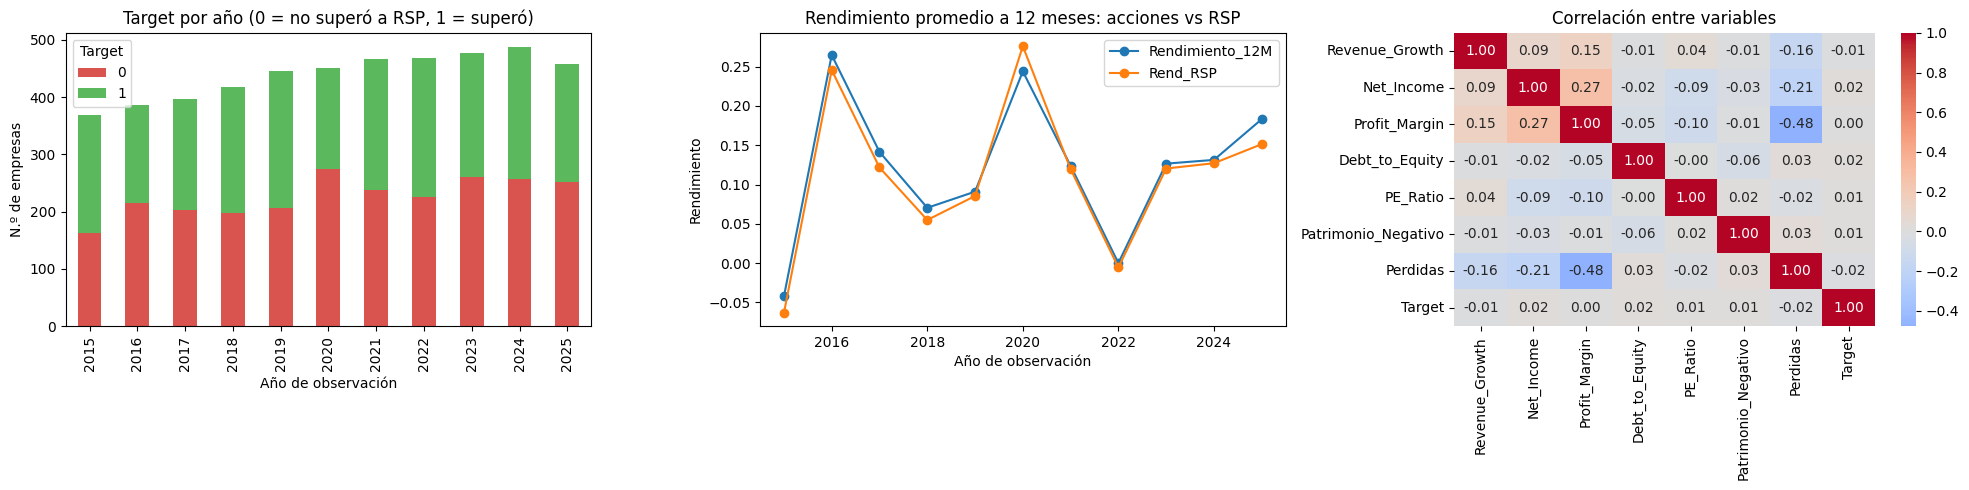

GICS Sector
Communication Services    41.0
Real Estate               41.0
Consumer Staples          42.0
Consumer Discretionary    43.0
Energy                    45.0
Materials                 46.0
Health Care               46.0
Industrials               52.0
Financials                52.0
Utilities                 53.0
Information Technology    57.0


In [36]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5))

tabla = panel.groupby(['Anio_Obs', 'Target']).size().unstack(fill_value=0)
tabla.plot(kind='bar', stacked=True, ax=axes[0], color=['#d9534f', '#5cb85c'][:tabla.shape[1]])
axes[0].set_title("Target por año (0 = no superó a RSP, 1 = superó)")
axes[0].set_xlabel("Año de observación"); axes[0].set_ylabel("N.º de empresas")

panel.groupby('Anio_Obs')[['Rendimiento_12M', 'Rend_RSP']].mean().plot(ax=axes[1], marker='o')
axes[1].set_title("Rendimiento promedio a 12 meses: acciones vs RSP")
axes[1].set_xlabel("Año de observación"); axes[1].set_ylabel("Rendimiento")

corr = panel[FEATURES_MODELO + ['Target']].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=axes[2])
axes[2].set_title("Correlación entre variables")
plt.tight_layout(); plt.show()

print((panel.groupby('GICS Sector')['Target'].mean().sort_values().round(2) * 100).rename("% que superó a RSP, por sector").to_string())

## Paso 9 – Exportación y entrega al compañero de ML

Se generan **dos archivos con las mismas filas y en el mismo orden**:

| Archivo | Quién lo usa | Contenido |
|---|---|---|
| `dataset_modelo.csv` | El compañero de ML, para entrenar | Solo números: features, sector en columnas 0/1 (*one-hot*), `Anio_Obs` y `Target`. **Sin nombres de empresas.** |
| `dataset_trazabilidad.csv` | Nosotros, para el informe | Ticker, nombre, sector, fechas, rendimientos reales de la acción, de RSP y de SPY, y el exceso. Sirve para explicar por qué el modelo acertó o falló en un caso concreto. |

**Variables excluidas del entrenamiento:**
- `Ticker` y `Security`: solo identifican; el modelo no debe memorizar empresas.
- `Rendimiento_12M`, `Rend_RSP`, `Rend_SPY`, `Exceso_vs_RSP`, `Target_vs_SPY`: el Target se calcula a partir de ellas → causarían *data leakage* (el modelo vería la respuesta).
- Fechas y precios: no son features.

### Recomendaciones para quien entrene los 3 modelos
1. **No usar `train_test_split` aleatorio.** Es un panel temporal: entrenar con los años anteriores y probar con los más recientes (por ejemplo entrenar con `Anio_Obs` ≤ 2021 y probar con 2022 en adelante). Un split aleatorio mezclaría el futuro con el pasado.
2. `Anio_Obs` está en el archivo **solo para hacer ese corte**; debe **quitarse de las features** al entrenar.
3. **Las clases no están 50/50.** No juzgar solo por *accuracy*: reportar también F1, ROC-AUC y la matriz de confusión; considerar `class_weight='balanced'`.
4. Escalar (`StandardScaler`) solo dentro de un `Pipeline` ajustado con train, para modelos sensibles a la escala (regresión logística, SVM, redes). Los árboles no lo necesitan.
5. La imputación y la winsorización se hicieron con datos del mismo año. Es aceptable; si se quiere ser estricto, puede rehacerse dentro de cada fold.

### Limitaciones para la sección correspondiente del informe
- **Sesgo de supervivencia:** las empresas que quebraron o fueron adquiridas casi no están en las fuentes gratuitas, así que el dataset es más optimista que la realidad. El rendimiento que mida el modelo probablemente esté sobreestimado.
- Sector desconocido para las empresas que ya salieron del índice.
- Etiquetas contables de la SEC no uniformes (deuda, ingresos de bancos).
- Este modelo es un ejercicio académico; no está validado para invertir dinero real.

In [38]:
df_trazabilidad = panel[['Ticker', 'Security', 'GICS Sector', 'Anio_Obs', 'Fecha_Obs', 'Fecha_Fin',
                         'Rendimiento_12M', 'Rend_RSP', 'Exceso_vs_RSP', 'Target',
                         'Rend_SPY', 'Target_vs_SPY']].copy()

df_modelo = pd.get_dummies(panel[['Anio_Obs', 'GICS Sector'] + FEATURES_MODELO + ['Target']],
                           columns=['GICS Sector'], dtype=int)
df_modelo = df_modelo[[c for c in df_modelo.columns if c != 'Target'] + ['Target']]

assert not df_modelo.isnull().any().any(), "Quedaron nulos en el dataset del modelo"
assert len(df_modelo) == len(df_trazabilidad)

df_modelo.to_csv("dataset_modelo.csv", index=False)
df_trazabilidad.to_csv("dataset_trazabilidad.csv", index=False)

print(f"✓ dataset_modelo.csv:        {df_modelo.shape}")
print(f"✓ dataset_trazabilidad.csv:  {df_trazabilidad.shape}")
print("\nColumnas del modelo:", list(df_modelo.columns))
print("\nDistribución del Target:", df_modelo['Target'].value_counts(normalize=True).round(3).to_dict())

# En Colab, quitar el # para descargar los archivos:
from google.colab import files
files.download("dataset_modelo.csv"); files.download("dataset_trazabilidad.csv")

✓ dataset_modelo.csv:        (4825, 20)
✓ dataset_trazabilidad.csv:  (4825, 12)

Columnas del modelo: ['Anio_Obs', 'Revenue_Growth', 'Net_Income', 'Profit_Margin', 'Debt_to_Equity', 'PE_Ratio', 'Patrimonio_Negativo', 'Perdidas', 'GICS Sector_Communication Services', 'GICS Sector_Consumer Discretionary', 'GICS Sector_Consumer Staples', 'GICS Sector_Energy', 'GICS Sector_Financials', 'GICS Sector_Health Care', 'GICS Sector_Industrials', 'GICS Sector_Information Technology', 'GICS Sector_Materials', 'GICS Sector_Real Estate', 'GICS Sector_Utilities', 'Target']

Distribución del Target: {0: 0.516, 1: 0.484}


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>